# 02 Procesamiento de texto, recuperación secuencial e indexación
### David Alejandro Puga Novoa
#### Recuperación de información
#### 28 de Octubre de 2026

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [1]:
# 1. Carga de textos originales y 2. Idenfiticación de número de documentos y tamaños
import nltk
import re
import time
import statistics
from nltk.corpus import gutenberg

nltk.download('gutenberg')

# 1. Cargar textos originales
file_ids = gutenberg.fileids()
raw_docs = {fid: gutenberg.raw(fid) for fid in file_ids}

# 2. Número de documentos y tamaños
print(f"Número de documentos: {len(raw_docs)}\n")
print(f"{'Documento':<30}{'Caracteres':>12}")
for fid, text in raw_docs.items():
    print(f"{fid:<30}{len(text):>12}")

Número de documentos: 18

Documento                       Caracteres
austen-emma.txt                     887071
austen-persuasion.txt               466292
austen-sense.txt                    673022
bible-kjv.txt                      4332554
blake-poems.txt                      38153
bryant-stories.txt                  249439
burgess-busterbrown.txt              84663
carroll-alice.txt                   144395
chesterton-ball.txt                 457450
chesterton-brown.txt                406629
chesterton-thursday.txt             320525
edgeworth-parents.txt               935158
melville-moby_dick.txt             1242990
milton-paradise.txt                 468220
shakespeare-caesar.txt              112310
shakespeare-hamlet.txt              162881
shakespeare-macbeth.txt             100351
whitman-leaves.txt                  711215


[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\biqo\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


In [2]:
# Implementación de tokenización y normalización
def tokenize(text):
    text = text.lower()
    # Solo letras con acentos y apóstrofes internos
    return re.findall(r"[a-záéíóúüñ]+(?:'[a-z]+)*", text)

# Corpus tokenizado: {doc_id: [tokens]}
docs = {fid: tokenize(text) for fid, text in raw_docs.items()}

total_tokens = sum(len(t) for t in docs.values())
print(f"Total de tokens: {total_tokens}")
for fid, toks in list(docs.items())[:3]:
    print(fid, toks[:10])

Total de tokens: 2118910
austen-emma.txt ['emma', 'by', 'jane', 'austen', 'volume', 'i', 'chapter', 'i', 'emma', 'woodhouse']
austen-persuasion.txt ['persuasion', 'by', 'jane', 'austen', 'chapter', 'sir', 'walter', 'elliot', 'of', 'kellynch']
austen-sense.txt ['sense', 'and', 'sensibility', 'by', 'jane', 'austen', 'chapter', 'the', 'family', 'of']


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [3]:
# Función de busqueda secuencial
def sequential_search(term, docs):
    term = tokenize(term)[0]  # misma normalización que el corpus
    result = []
    for doc_id, tokens in docs.items():
        for token in tokens:
            if token == term:
                result.append(doc_id)
                break  # ya sabemos que el documento lo contiene
    return result

In [4]:
# Elegir consultas (solo para escoger términos, no se usa en la búsqueda)
from collections import Counter

df = Counter()
for tokens in docs.values():
    df.update(set(tokens))

print("Frecuentes (DF = 18):", [t for t, c in df.items() if c == len(docs)][:10])
print("Poco frecuentes (DF = 1):", [t for t, c in df.items() if c == 1][:10])

Frecuentes (DF = 18): ['had', 'has', 'man', 'when', 'more', 'whose', 'night', 'sweet', 'both', 'let']
Poco frecuentes (DF = 1): ['unexceptionably', 'unbleached', 'treasuring', 'conditionally', "larkins's", 'bewitches', 'unseasonableness', 'hautboy', 'importation', 'rubbers']


In [5]:
# Ejecutar consultas
queries = {
    "frecuente": "you",
    "poco frecuente": "latterly", # Término poco frecuente encontrado anteriomente. DF=1
    "inexistente": "asdfghjklñ",
}

for tipo, q in queries.items():
    res = sequential_search(q, docs)
    print(f"{tipo:<15} '{q}': {len(res)} docs -> {res}")

frecuente       'you': 18 docs -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
poco frecuente  'latterly': 1 docs -> ['austen-emma.txt']
inexistente     'asdfghjklñ': 0 docs -> []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [6]:
# Función de medición de tiempo
def measure(func, *args, runs=30):
    times = []
    for _ in range(runs):
        start = time.perf_counter_ns()
        func(*args)
        end = time.perf_counter_ns()
        times.append(end - start)
    return statistics.mean(times) / 1e6  #-> ms

In [7]:
# Tiempo de la busqueda secuencial con la función de medición
print(f"{'Tipo':<16}{'Consulta':<14}{'Docs':>6}{'Tiempo medio (ms)':>20}")
for tipo, q in queries.items():
    t = measure(sequential_search, q, docs)
    n_res = len(sequential_search(q, docs))
    print(f"{tipo:<16}{q:<14}{n_res:>6}{t:>20.4f}")

Tipo            Consulta        Docs   Tiempo medio (ms)
frecuente       you               18              0.1208
poco frecuente  latterly           1             13.7014
inexistente     asdfghjklñ         0             13.4197


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [8]:
# Construcción del índice
def build_inverted_index(docs):
    index = {}
    for doc_id, tokens in docs.items():
        for token in set(tokens):          # set: una vez por doc
            index.setdefault(token, []).append(doc_id)
    for term in index:
        index[term].sort()
    return index

index = build_inverted_index(docs)
all_doc_ids = sorted(docs.keys())
print(f"Tamaño del vocabulario: {len(index)}")

Tamaño del vocabulario: 43494


In [9]:
# Encontrar términos medios (con un DF entre 5 y 12)
medios = [t for t, c in df.items() if 5 <= c <= 12]
print(medios)

['guided', 'confine', 'sly', "morning's", 'bench', 'extinction', 'unwilling', 'reverse', 'positive', 'k', 'ardent', 'club', 'calls', 'witness', 'partake', 'wrist', 'accomplishment', 'exchange', 'usual', 'discipline', 'expose', 'terribly', 'future', 'adjoining', 'maintained', 'hum', 'previously', 'rescue', 'shoes', 'sons', 'lamb', 'flight', 'fearfully', 'mansion', 'gradual', 'sincere', 'cakes', 'vigour', 'struggle', 'placing', 'offices', 'infinite', 'fewer', 'mill', 'throws', 'employments', 'insisted', 'requiring', 'lane', 'gain', 'deemed', 'renewing', 'purposely', 'faithful', 'autumn', 'meadows', 'occur', 'orders', 'cheerfulness', 'indulgence', 'mounted', 'coloured', 'devil', 'staying', 'grateful', 'sadly', 'wan', 'discourse', 'pressed', 'prefer', 'plentiful', 'urgent', 'unwelcome', 'portrait', 'sincerely', 'rode', 'propriety', 'bonnet', 'contentment', 'instance', 'genius', 'mistakes', 'firm', 'sunshine', 'deserved', 'mournful', 'measures', 'courtesies', 'philip', 'decent', 'portion', 

In [10]:
# Postings y DF
def df_of(term, index):
    return len(index.get(term, []))

for t in ["you", "latterly", "management", "ope", "asdfghjklñ"]:
    print(f"{t:<12} DF={df_of(t, index):<3} postings={index.get(t, [])}")

you          DF=18  postings=['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
latterly     DF=1   postings=['austen-emma.txt']
management   DF=6   postings=['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'chesterton-ball.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt']
ope          DF=5   postings=['milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
asdfghjklñ   DF=0   postings=[]


In [11]:
# Consultas de un término y booleanas
def idx_term(term, index):
    term = tokenize(term)[0]
    return index.get(term, [])

def idx_and(a, b, index):
    return sorted(set(idx_term(a, index)) & set(idx_term(b, index)))

def idx_or(a, b, index):
    return sorted(set(idx_term(a, index)) | set(idx_term(b, index)))

def idx_not(a, index, universe=all_doc_ids):
    return sorted(set(universe) - set(idx_term(a, index)))

print("management:", idx_term("management", index))
print("management AND merrily:", idx_and("management", "merrily", index))
print("ope OR management:", idx_or("ope", "management", index))
print("NOT management:", idx_not("management", index))

management: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'chesterton-ball.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt']
management AND merrily: ['edgeworth-parents.txt', 'melville-moby_dick.txt']
ope OR management: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'chesterton-ball.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
NOT management: ['bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [12]:
# Booleanas secuenciales
def seq_and(a, b, docs):
    return sorted(set(sequential_search(a, docs)) & set(sequential_search(b, docs)))

def seq_or(a, b, docs):
    return sorted(set(sequential_search(a, docs)) | set(sequential_search(b, docs)))

def seq_not(a, docs):
    return sorted(set(docs.keys()) - set(sequential_search(a, docs)))

In [13]:
# Comparación (resultados + tiempos)
# (etiqueta, función secuencial, función con índice)
tests = [
    ("you (frecuente)",       lambda: sorted(sequential_search("you", docs)),        lambda: idx_term("you", index)),
    ("latterly (raro)",       lambda: sorted(sequential_search("latterly", docs)),   lambda: idx_term("latterly", index)),
    ("asdfghjklñ (inexist.)", lambda: sorted(sequential_search("asdfghjklñ", docs)), lambda: idx_term("asdfghjklñ", index)),
    ("management AND merrily",lambda: seq_and("management", "merrily", docs),        lambda: idx_and("management", "merrily", index)),
    ("ope OR management",     lambda: seq_or("ope", "managment", docs),              lambda: idx_or("ope", "managment", index)),
    ("NOT management",        lambda: seq_not("management", docs),                   lambda: idx_not("management", index)),
]

print(f"{'Consulta':<24}{'Iguales':>8}{'Secuencial (ms)':>18}{'Índice (ms)':>14}{'Speedup':>10}")
for label, f_seq, f_idx in tests:
    same = sorted(f_seq()) == sorted(f_idx())
    t_seq = measure(f_seq)
    t_idx = measure(f_idx)
    print(f"{label:<24}{str(same):>8}{t_seq:>18.4f}{t_idx:>14.6f}{t_seq/t_idx:>10.0f}x")

Consulta                 Iguales   Secuencial (ms)   Índice (ms)   Speedup
you (frecuente)             True            0.1234      0.000490       252x
latterly (raro)             True           14.3620      0.000893     16077x
asdfghjklñ (inexist.)       True           13.7746      0.000807     17076x
management AND merrily      True           20.1182      0.001583     12706x
ope OR management           True           34.0088      0.001580     21525x
NOT management              True           11.1357      0.001633      6818x


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [14]:
# Imports y ruta
import zipfile, tarfile, re, json, time, os, random, sys

ZIP_PATH = r"D:\Carpeta Vid\Archivos\Universidad\7to Semestre\Recuperacion de la Informacion\Notebooks\txt-files.tar.zip"
pattern = re.compile(r"^cache/epub/(\d+)/pg(\d+)\.txt$")

In [15]:
# Explorar el contenido (el zip trae un único txt-files.tar)
with zipfile.ZipFile(ZIP_PATH) as z:
    infos = z.infolist()
    print("Entradas dentro del zip:", len(infos))
    for info in infos[:5]:
        print(info.filename, info.file_size)

with zipfile.ZipFile(ZIP_PATH) as z:
    with z.open("txt-files.tar") as f:
        with tarfile.open(fileobj=f, mode="r|") as tar:
            for i, member in enumerate(tar):
                print(member.name, member.size, member.isfile())
                if i >= 19:
                    break

Entradas dentro del zip: 1
txt-files.tar 30623477760
cache/epub/10000/pg10000.txt 101742 True
cache/epub/10001/pg10001.txt 50987 True
cache/epub/10002/pg10002.txt 305330 True
cache/epub/10003/pg10003.txt 379938 True
cache/epub/10004/pg10004.txt 301281 True
cache/epub/10005/pg10005.txt 433229 True
cache/epub/10006/pg10006.txt 94352 True
cache/epub/10007/pg10007.txt 181071 True
cache/epub/10008/pg10008.txt 405675 True
cache/epub/10009/pg10009.txt 502864 True
cache/epub/1000/pg1000.txt 597903 True
cache/epub/10010/pg10010.txt 84951 True
cache/epub/10011/pg10011.txt 154063 True
cache/epub/10012/pg10012.txt 561602 True
cache/epub/10013/pg10013.txt 135173 True
cache/epub/10014/pg10014.txt 140968 True
cache/epub/10015/pg10015.txt 136972 True
cache/epub/10016/pg10016.txt 145801 True
cache/epub/10017/pg10017.txt 134798 True
cache/epub/10018/pg10018.txt 138192 True


In [16]:
# Contar documentos válidos
valid = {}
otros = 0
t0 = time.time()

with zipfile.ZipFile(ZIP_PATH) as z:
    with z.open("txt-files.tar") as f:
        with tarfile.open(fileobj=f, mode="r|") as tar:
            for member in tar:
                if not member.isfile():
                    continue
                m = pattern.match(member.name)
                if m and m.group(1) == m.group(2) and member.size > 0:
                    valid[int(m.group(1))] = member.name
                else:
                    otros += 1

print(f"Tiempo: {(time.time() - t0)/60:.1f} min")
print(f"Documentos válidos: {len(valid)}")
print(f"Archivos descartados: {otros}")

with open("gutenberg_valid_ids.json", "w") as fp:
    json.dump(sorted(valid.keys()), fp)

Tiempo: 1.7 min
Documentos válidos: 78145
Archivos descartados: 0


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [17]:
# Subconjunto reproducible de 1000 libros
with open("gutenberg_valid_ids.json") as fp:
    all_ids = json.load(fp)

random.seed(42)
shuffled = all_ids[:]
random.shuffle(shuffled)

N_MAX = 1000
subset_ids = shuffled[:N_MAX]      # el subconjunto de tamaño n es subset_ids[:n]
wanted = set(subset_ids)

with open("subset_ids_order.json", "w") as fp:
    json.dump(subset_ids, fp)

os.makedirs("subset", exist_ok=True)

found = 0
t0 = time.time()
with zipfile.ZipFile(ZIP_PATH) as z:
    with z.open("txt-files.tar") as f:
        with tarfile.open(fileobj=f, mode="r|") as tar:
            for member in tar:
                if not member.isfile():
                    continue
                m = pattern.match(member.name)
                if not m:
                    continue
                book_id = int(m.group(1))
                if book_id in wanted:
                    data = tar.extractfile(member).read()
                    with open(f"subset/{book_id}.txt", "wb") as out:
                        out.write(data)
                    found += 1
                    if found == N_MAX:
                        break

print(f"Tiempo: {(time.time() - t0)/60:.1f} min")
print(f"Extraídos: {found}")
total_bytes = sum(os.path.getsize(f"subset/{i}.txt") for i in subset_ids)
print(f"Espacio en disco del subconjunto: {total_bytes/1e6:.1f} MB")

Tiempo: 1.7 min
Extraídos: 1000
Espacio en disco del subconjunto: 417.7 MB


In [18]:
# Cargar y tokenizar con la misma normalización
try:
    import psutil
except ImportError:
    !pip install psutil
    import psutil

proc = psutil.Process(os.getpid())
def rss_mb():
    return proc.memory_info().rss / 1e6

def load_tokens(book_id):
    with open(f"subset/{book_id}.txt", encoding="utf-8", errors="ignore") as f:
        text = f.read()
    return [sys.intern(t) for t in tokenize(text)]

with open("subset_ids_order.json") as fp:
    subset_ids = json.load(fp)

mem_before = rss_mb()
t0 = time.time()

docs_large = {}
for i, bid in enumerate(subset_ids, 1):
    docs_large[bid] = load_tokens(bid)
    if i % 200 == 0:
        print(f"{i} docs | RAM: {rss_mb():.0f} MB | {(time.time()-t0)/60:.1f} min")

total_tokens_large = sum(len(t) for t in docs_large.values())
print(f"\nTiempo: {(time.time()-t0)/60:.1f} min")
print(f"Documentos: {len(docs_large)}")
print(f"Total de tokens: {total_tokens_large}")
print(f"RAM antes: {mem_before:.0f} MB | después: {rss_mb():.0f} MB")

200 docs | RAM: 695 MB | 0.1 min
400 docs | RAM: 823 MB | 0.1 min
600 docs | RAM: 921 MB | 0.2 min
800 docs | RAM: 1031 MB | 0.2 min
1000 docs | RAM: 1130 MB | 0.3 min

Tiempo: 0.3 min
Documentos: 1000
Total de tokens: 66934177
RAM antes: 314 MB | después: 1130 MB


In [19]:
# Indice invertido del corpus grande
mem_before_idx = rss_mb()
t0 = time.perf_counter()

index_large = build_inverted_index(docs_large)   # misma función de la Parte A

t_build = time.perf_counter() - t0
mem_after_idx = rss_mb()
n_postings = sum(len(p) for p in index_large.values())

print(f"Tiempo de construcción: {t_build:.1f} s")
print(f"Vocabulario: {len(index_large)} términos")
print(f"Postings totales: {n_postings}")
print(f"RAM del índice: {mem_after_idx - mem_before_idx:.0f} MB (total proceso: {mem_after_idx:.0f} MB)")

Tiempo de construcción: 4.9 s
Vocabulario: 1043438 términos
Postings totales: 6928697
RAM del índice: 161 MB (total proceso: 1291 MB)


In [20]:
# Elegir consultas según DF
N = len(docs_large)
frecuentes = [t for t, p in index_large.items() if len(p) == N and t.isalpha()][:10]
medios     = [t for t, p in index_large.items() if 100 <= len(p) <= 400 and t.isalpha() and len(t) > 5][:10]
raros      = [t for t, p in index_large.items() if len(p) == 1 and t.isalpha() and len(t) > 6][:10]

print("Frecuentes (DF = 1000):", frecuentes)
print("DF intermedio:", [(t, len(index_large[t])) for t in medios])
print("Raros (DF = 1):", raros)

Frecuentes (DF = 1000): ['reasonable', 'paying', 'learn', 'end', 'copying', 'displayed', 'electronically', 'current', 'while', 'tax']
DF intermedio: [('pierre', 158), ('translator', 149), ('extinguished', 193), ('stakes', 127), ('fountain', 269), ('handled', 278), ('unwilling', 279), ('positive', 364), ('fascinated', 170), ('implored', 128)]
Raros (DF = 1): ['raoulin', 'uhraavaisuudella', 'arvoisata', 'palvelianne', 'majesteetillisunden', 'oikkunsakin', 'vallitsemisessaan', 'lailliseen', 'atrialle', 'rohkeamielisyytesi']


In [21]:
# Comparación de resultados y tiempos
universe_large = sorted(docs_large.keys())

tests_large = [
    ("in (frecuente)",         lambda: sorted(sequential_search("in", docs_large)),         lambda: idx_term("in", index_large)),
    ("management (medio)",     lambda: sorted(sequential_search("management", docs_large)), lambda: idx_term("management", index_large)),
    ("lienettek (raro)",       lambda: sorted(sequential_search("lienettek", docs_large)),  lambda: idx_term("lienettek", index_large)),
    ("asdfghjklñ (inexist.)",  lambda: sorted(sequential_search("asdfghjklñ", docs_large)), lambda: idx_term("asdfghjklñ", index_large)),
    ("management AND pierre",  lambda: seq_and("management", "pierre", docs_large),         lambda: idx_and("management", "pierre", index_large)),
    ("translator OR pierre",   lambda: seq_or("translator", "pierre", docs_large),          lambda: idx_or("translator", "pierre", index_large)),
    ("NOT management",         lambda: seq_not("management", docs_large),                   lambda: idx_not("management", index_large, universe_large)),
]

print(f"{'Consulta':<24}{'Iguales':>8}{'Docs':>6}{'Secuencial (ms)':>18}{'Índice (ms)':>14}{'Speedup':>10}")
for label, f_seq, f_idx in tests_large:
    r_seq, r_idx = f_seq(), f_idx()
    same = sorted(r_seq) == sorted(r_idx)
    t_seq = measure(f_seq)
    t_idx = measure(f_idx)
    print(f"{label:<24}{str(same):>8}{len(r_idx):>6}{t_seq:>18.2f}{t_idx:>14.6f}{t_seq/t_idx:>10.0f}x")

Consulta                 Iguales  Docs   Secuencial (ms)   Índice (ms)   Speedup
in (frecuente)              True  1000              0.24      0.000540       439x
management (medio)          True   275            517.24      0.000867    596811x
lienettek (raro)            True     1            951.96      0.000847   1124367x
asdfghjklñ (inexist.)       True     0            887.52      0.000920    964696x
management AND pierre       True    48           1137.08      0.008577    132578x
translator OR pierre        True   271           1246.65      0.018410     67716x
NOT management              True   725            778.33      0.119513      6512x


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

In [22]:
# Experimento de escalabilidad
import pandas as pd

QUERY = "asdfghjklñ"
sizes = [50, 100, 250, 500, 1000]

rows = []
for n in sizes:
    ids_n = subset_ids[:n] # subconjuntos anidados
    docs_n = {bid: docs_large[bid] for bid in ids_n}
    tokens_n = sum(len(t) for t in docs_n.values())

    # Búsqueda secuencial: 30 ejecuciones
    t_seq = measure(sequential_search, QUERY, docs_n)

    # Índice del subconjunto
    t0 = time.perf_counter()
    index_n = build_inverted_index(docs_n)
    t_build = time.perf_counter() - t0

    # Consulta con índice: 30 ejecuciones
    t_idx = measure(idx_term, QUERY, index_n)

    # Comprobación de igualdad
    assert sorted(sequential_search(QUERY, docs_n)) == sorted(idx_term(QUERY, index_n))

    rows.append({"n_docs": n, "tokens": tokens_n,
                 "t_seq_ms": t_seq, "t_idx_ms": t_idx,
                 "build_idx_s": t_build})
    print(f"n={n:<5} tokens={tokens_n:<10} seq={t_seq:.2f} ms  idx={t_idx:.6f} ms  build={t_build:.2f} s")

df_res = pd.DataFrame(rows)
df_res

n=50    tokens=3009809    seq=56.07 ms  idx=0.002423 ms  build=0.92 s
n=100   tokens=5845126    seq=110.97 ms  idx=0.002310 ms  build=0.41 s
n=250   tokens=20797024   seq=428.96 ms  idx=0.001987 ms  build=3.06 s
n=500   tokens=35959016   seq=744.92 ms  idx=0.001080 ms  build=3.35 s
n=1000  tokens=66934177   seq=953.74 ms  idx=0.001140 ms  build=3.60 s


,n_docs,tokens,t_seq_ms,t_idx_ms,build_idx_s
0,50,3009809,56.073460,0.002423,0.922205
1,100,5845126,110.968137,0.002310,0.407068
2,250,20797024,428.960500,0.001987,3.058577
3,500,35959016,744.916227,0.001080,3.353678
4,1000,66934177,953.741967,0.001140,3.597506


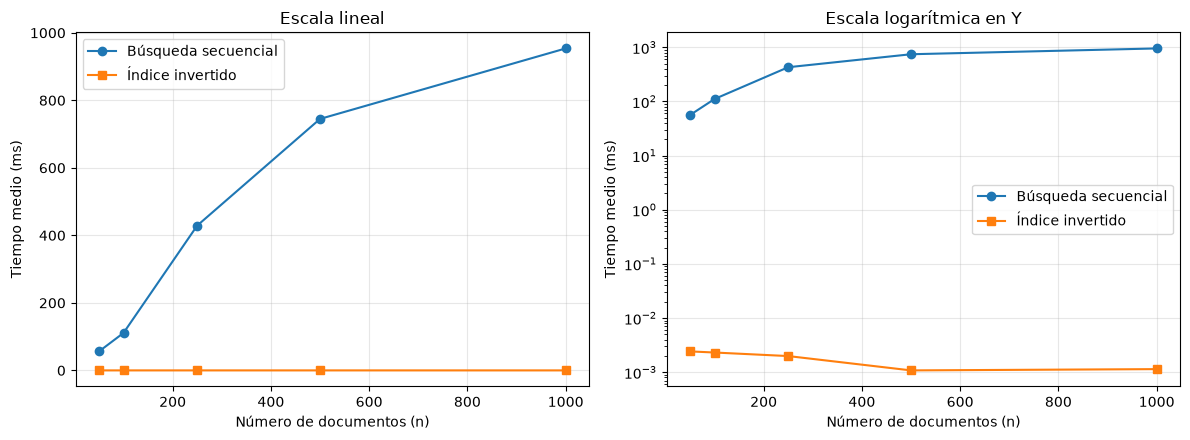

In [23]:
# Gráfica (ambos métodos)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, log in zip(axes, [False, True]):
    ax.plot(df_res["n_docs"], df_res["t_seq_ms"], "o-", label="Búsqueda secuencial")
    ax.plot(df_res["n_docs"], df_res["t_idx_ms"], "s-", label="Índice invertido")
    ax.set_xlabel("Número de documentos (n)")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.grid(alpha=0.3)
    ax.legend()
    if log:
        ax.set_yscale("log")
        ax.set_title("Escala logarítmica en Y")
    else:
        ax.set_title("Escala lineal")

plt.tight_layout()
plt.show()

- El costo de la secuencial depende de los tokens, no del número de documentos, y los libros varían mucho de tamaño. Por eso de 500 a 1000 docs los tokens casi se duplican (36 M → 67 M) pero el tiempo sube solo de 749 a 911 ms. Esto hace que el ajuste contra n no sea perfecto.
- La variación del índice (0,0020 a 0,0025 ms) es ruido de medición, no crecimiento.

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

In [24]:
# Ajuste Lineal t(n) = an + b y R^2
import numpy as np

def fit_linear(x, y):
    a, b = np.polyfit(x, y, 1)
    y_hat = a * x + b
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - ss_res / ss_tot
    return a, b, r2

n = df_res["n_docs"].to_numpy(dtype=float)
fits = {}
for col, nombre in [("t_seq_ms", "Búsqueda secuencial"), ("t_idx_ms", "Índice invertido")]:
    a, b, r2 = fit_linear(n, df_res[col].to_numpy())
    fits[col] = (a, b, r2)
    print(f"{nombre:<22} a = {a:.6g} ms/doc | b = {b:.6g} ms | R^2 = {r2:.4f}")

Búsqueda secuencial    a = 0.954179 ms/doc | b = 96.3441 ms | R^2 = 0.8987
Índice invertido       a = -1.44008e-06 ms/doc | b = 0.00233523 ms | R^2 = 0.7640


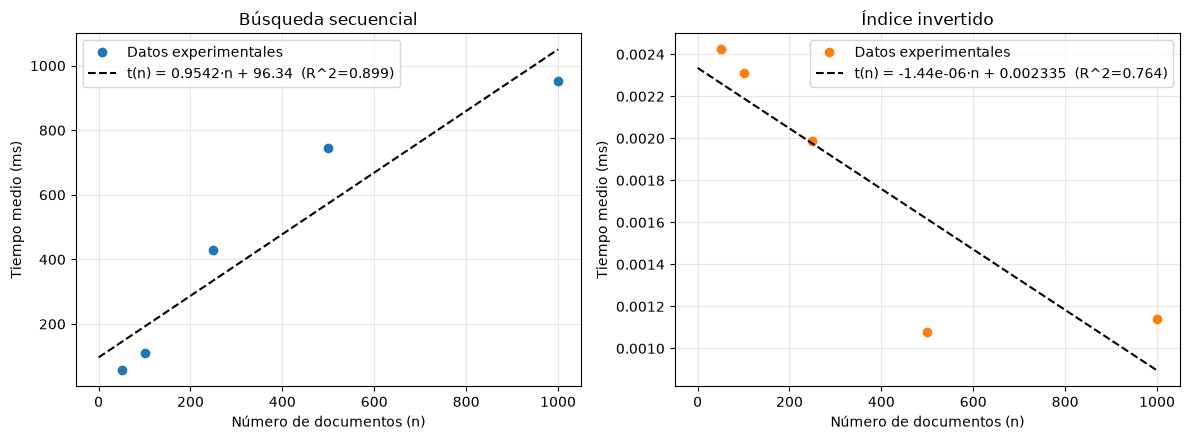

In [25]:
# Funciones ajustadas junto a los datos
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
n_line = np.linspace(0, 1000, 200)

for ax, col, nombre, color in [
    (axes[0], "t_seq_ms", "Búsqueda secuencial", "tab:blue"),
    (axes[1], "t_idx_ms", "Índice invertido", "tab:orange"),
]:
    a, b, r2 = fits[col]
    ax.plot(df_res["n_docs"], df_res[col], "o", color=color, label="Datos experimentales")
    ax.plot(n_line, a * n_line + b, "--", color="k", label=f"t(n) = {a:.4g}·n + {b:.4g}  (R^2={r2:.3f})")
    ax.set_xlabel("Número de documentos (n)")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.set_title(nombre)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [26]:
# Ajuste contra tokens
tok = df_res["tokens"].to_numpy(dtype=float)
a_t, b_t, r2_t = fit_linear(tok, df_res["t_seq_ms"].to_numpy())
print(f"Secuencial vs tokens: a = {a_t:.4g} ms/token | b = {b_t:.4g} ms | R^2 = {r2_t:.4f}")

Secuencial vs tokens: a = 1.445e-05 ms/token | b = 75.8 ms | R^2 = 0.9353


**Análisis del ajuste lineal t(n) = an + b**

| Método | a | b | R² |
|---|---|---|---|
| Búsqueda secuencial | 0,954 ms/doc | 96,3 ms | 0,899 |
| Índice invertido | −1,44·10⁻⁶ ms/doc | 0,00234 ms | 0,764 |

**Búsqueda secuencial.** 

El modelo lineal representa razonablemente la tendencia (R² ≈ 0,90): el tiempo crece al aumentar el corpus, con una pendiente de ~0,95 ms por documento. Sin embargo, el ajuste no es perfecto: los puntos de n = 250 y n = 500 se desvían de la recta, y el intercepto b ≈ 96 ms no tiene sentido físico (con 0 documentos el tiempo debería ser ~0). Ambas cosas se explican porque el costo depende del número total de tokens recorridos y no del número de documentos, y los libros tienen longitudes muy distintas. Al ajustar contra los tokens el R² sube a 0,935 (a ≈ 1,45·10⁻⁵ ms/token, es decir, ~14,5 ns por token), lo que confirma que esa es la variable que realmente gobierna el costo. El intercepto también baja (b ≈ 76 ms), aunque no desaparece del todo, lo que sugiere que intervienen otros factores como la caché de memoria, el recolector de basura de Python y el ruido de medición. Con solo cinco puntos, el ajuste además es sensible a valores atípicos.

**Relación con la complejidad.** 

La búsqueda secuencial es O(N), con N el total de tokens (O(n·L̄), con L̄ la longitud media de los documentos). Es lineal en n solo si L̄ es aproximadamente constante, de ahí que el modelo lineal sea una buena aproximación pero no exacta. La consulta usada (término inexistente) corresponde al peor caso, pues recorre todo el corpus.

**Índice invertido.** 

Aunque el R² (0,90) parece alto, el ajuste no es interpretable: la pendiente es negativa (−1,4·10⁻⁶ ms/doc), lo que implicaría que el índice se acelera con más documentos, algo imposible. Las mediciones son de ~1 a 2 µs, y la variación total (≈ 1,4 µs entre n = 50 y n = 1000) es del orden del ruido del temporizador y del sistema. El R² alto es un artefacto de ajustar una recta a 5 puntos ruidosos. La conclusión correcta es que el tiempo es prácticamente constante e independiente de n, lo que concuerda con la complejidad esperada: consultar un término es una búsqueda en una tabla hash, O(1) en promedio. Las consultas booleanas son O(|postings|), que sí crece con n, pero siguen siendo órdenes de magnitud más rápidas que recorrer los tokens.

**Costo de construcción.** 

El índice no es gratis: construirlo es O(N) (5,4 s y ~158 MB de RAM para 1000 documentos), pero se amortiza tras pocas consultas, ya que cada consulta secuencial cuesta cerca de 1 s a ese tamaño.